# NOTEBOOK 05: MODEL EVALUATION & SHAP EXPLAINABILITY
In this notebook, we perform:
- Benchmark between Best Machine Learning Model (XGBoost) and Deep Learning (PyTorch MLP).
- Confusion Matrices, Classification Reports, ROC-AUC curves.
- **SHAP (SHapley Additive exPlanations)** for global feature importance and individual patient prediction interpretability.


In [1]:
import os
import sys
import json
import joblib
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score

sys.path.append(os.path.join("..", "training_scripts"))
from data_loader import prepare_splits, FEATURE_COLUMNS, SAVED_MODELS_DIR
from train_dl import DiabetesMLP

data = prepare_splits()
X_test, y_test = data['X_test'], data['y_test']

ml_model = joblib.load(os.path.join(SAVED_MODELS_DIR, "diabetes_model.pkl"))
dl_model = DiabetesMLP(input_dim=8)
dl_model.load_state_dict(torch.load(os.path.join(SAVED_MODELS_DIR, "diabetes_dl_model.pth")))
dl_model.eval()


C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DiabetesMLP(
  (net): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)

### 5.1 Test Set Confusion Matrix Comparison (XGBoost vs PyTorch MLP)

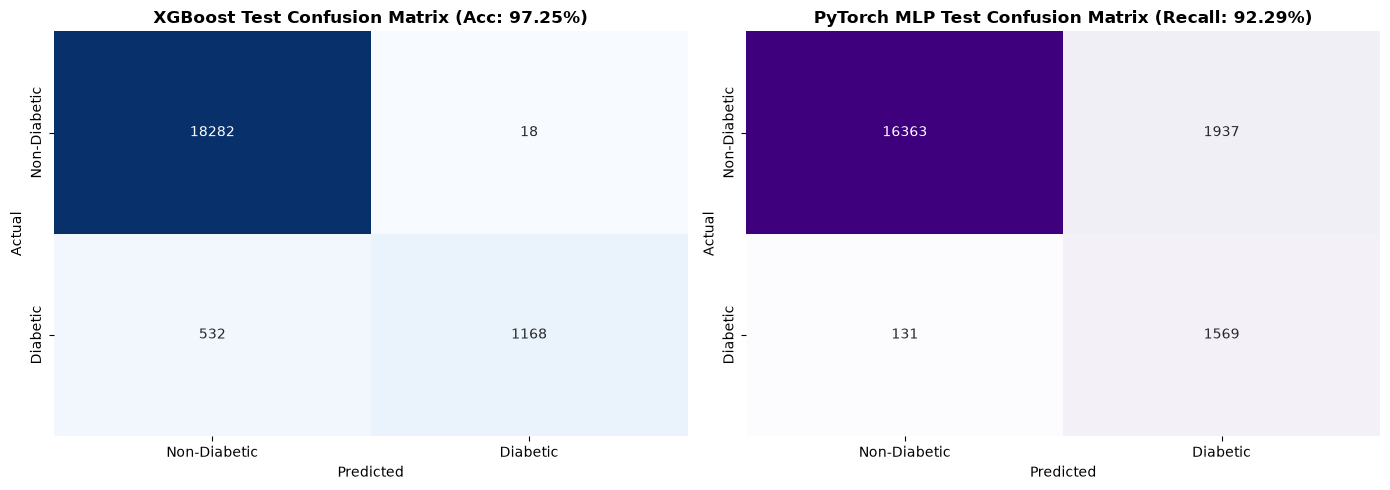

In [2]:
# ML Predictions
y_pred_ml = ml_model.predict(X_test)
cm_ml = confusion_matrix(y_test, y_pred_ml)

# DL Predictions
with torch.no_grad():
    y_prob_dl = torch.sigmoid(dl_model(torch.tensor(X_test, dtype=torch.float32))).cpu().numpy().flatten()
    y_pred_dl = (y_prob_dl >= 0.5).astype(int)
cm_dl = confusion_matrix(y_test, y_pred_dl)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm_ml, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Non-Diabetic', 'Diabetic'], yticklabels=['Non-Diabetic', 'Diabetic'])
axes[0].set_title(f"XGBoost Test Confusion Matrix (Acc: {np.mean(y_pred_ml==y_test)*100:.2f}%)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(cm_dl, annot=True, fmt='d', cmap='Purples', ax=axes[1], cbar=False,
            xticklabels=['Non-Diabetic', 'Diabetic'], yticklabels=['Non-Diabetic', 'Diabetic'])
axes[1].set_title(f"PyTorch MLP Test Confusion Matrix (Recall: {np.sum((y_pred_dl==1)&(y_test==1))/np.sum(y_test==1)*100:.2f}%)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


### 5.2 Global SHAP Feature Importance (Bar Chart & Beeswarm Plot)

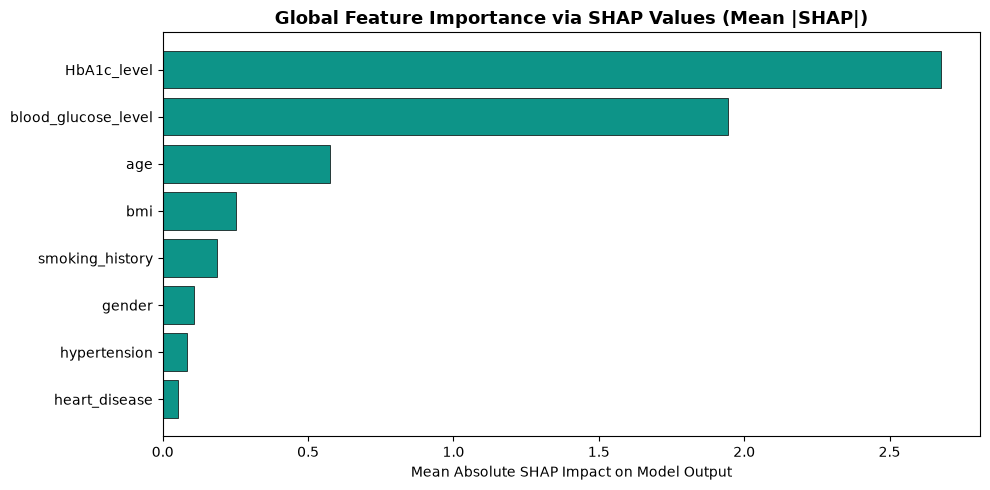

In [3]:
explainer = shap.TreeExplainer(ml_model)
sample_X = X_test[:300]
shap_values = explainer.shap_values(sample_X)
if isinstance(shap_values, list) and len(shap_values) == 2:
    shap_values = shap_values[1]

# Global Bar Chart
mean_shap = np.mean(np.abs(shap_values), axis=0)
shap_df = pd.DataFrame({"Feature": FEATURE_COLUMNS, "Mean_Absolute_SHAP": mean_shap})
shap_df = shap_df.sort_values(by="Mean_Absolute_SHAP", ascending=True)

plt.figure(figsize=(10, 5))
plt.barh(shap_df['Feature'], shap_df['Mean_Absolute_SHAP'], color='#0d9488', edgecolor='black', linewidth=0.5)
plt.title("Global Feature Importance via SHAP Values (Mean |SHAP|)", fontsize=13, fontweight='bold')
plt.xlabel("Mean Absolute SHAP Impact on Model Output")
plt.tight_layout()
plt.show()


### 5.3 SHAP Beeswarm Summary Plot (Direction of Feature Impact)

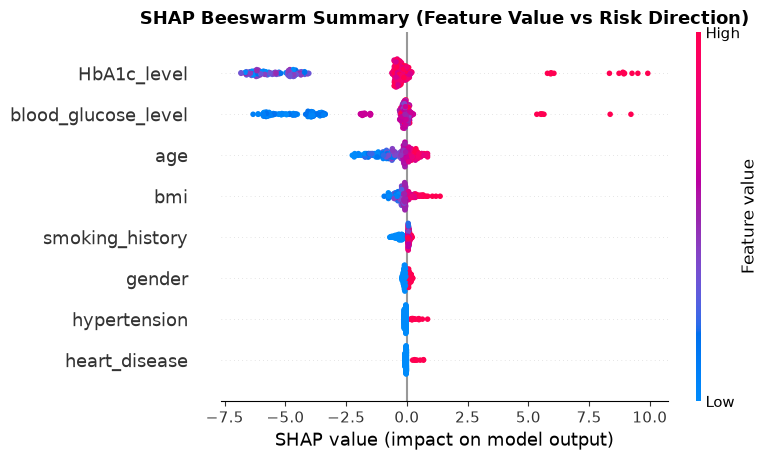

In [4]:
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, sample_X, feature_names=FEATURE_COLUMNS, show=False)
plt.title("SHAP Beeswarm Summary (Feature Value vs Risk Direction)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 5.4 Individual Patient Local Prediction Interpretability (SHAP Waterfall/Local Bar)

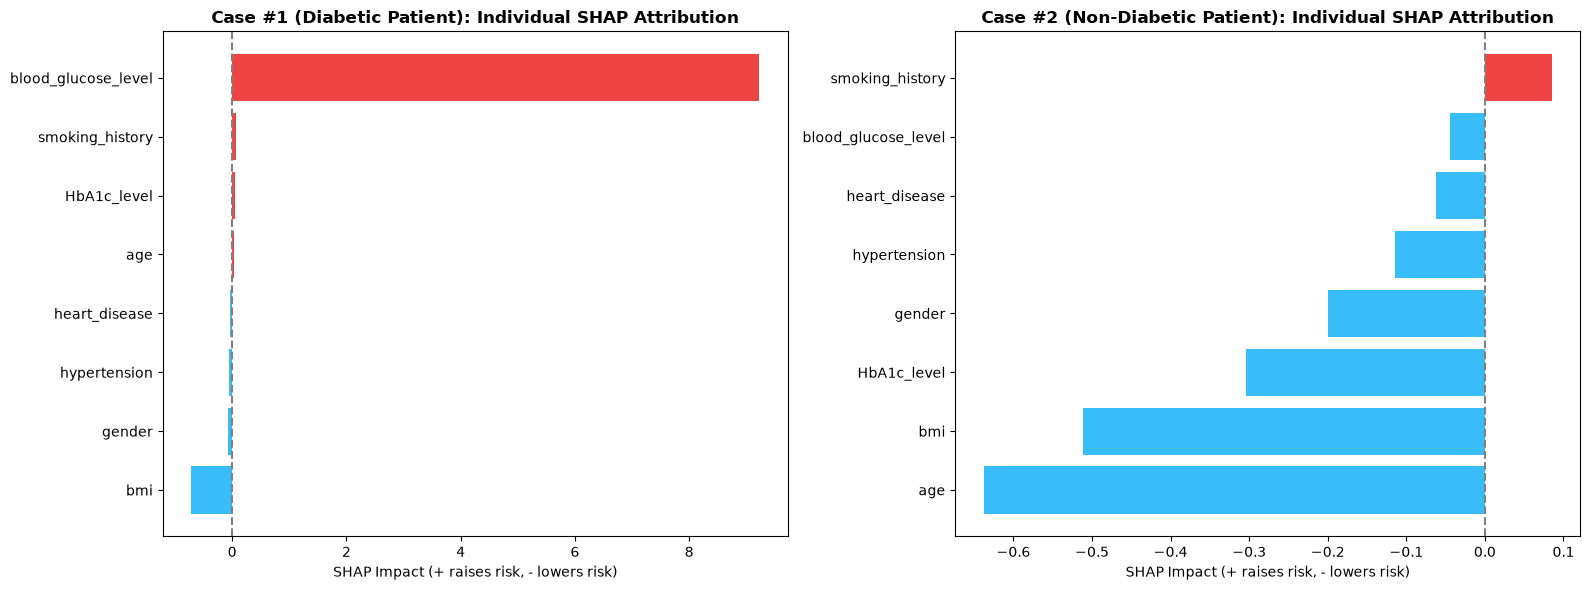

In [5]:
# Compare a High Risk Patient vs Low Risk Patient
high_risk_idx = np.where(y_test == 1)[0][0]
low_risk_idx = np.where(y_test == 0)[0][0]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# High risk patient contribution
high_shap = explainer.shap_values(X_test[high_risk_idx:high_risk_idx+1])
if isinstance(high_shap, list): high_shap = high_shap[1]
high_series = pd.Series(high_shap[0], index=FEATURE_COLUMNS).sort_values()

axes[0].barh(high_series.index, high_series.values, color=['#ef4444' if x > 0 else '#38bdf8' for x in high_series.values])
axes[0].set_title(f"Case #1 (Diabetic Patient): Individual SHAP Attribution", fontsize=12, fontweight='bold')
axes[0].set_xlabel("SHAP Impact (+ raises risk, - lowers risk)")
axes[0].axvline(0, color='gray', linestyle='--')

# Low risk patient contribution
low_shap = explainer.shap_values(X_test[low_risk_idx:low_risk_idx+1])
if isinstance(low_shap, list): low_shap = low_shap[1]
low_series = pd.Series(low_shap[0], index=FEATURE_COLUMNS).sort_values()

axes[1].barh(low_series.index, low_series.values, color=['#ef4444' if x > 0 else '#38bdf8' for x in low_series.values])
axes[1].set_title(f"Case #2 (Non-Diabetic Patient): Individual SHAP Attribution", fontsize=12, fontweight='bold')
axes[1].set_xlabel("SHAP Impact (+ raises risk, - lowers risk)")
axes[1].axvline(0, color='gray', linestyle='--')

plt.tight_layout()
plt.show()
